# EE136 — Train 3-block 1D CNN trên GPU Windows (local)

Đặt `features_train.zip` cùng thư mục với notebook; mở bằng Jupyter Notebook / VS Code. Chọn đúng Python environment đã cài PyTorch GPU. Chạy tuần tự từ trên xuống.

Mô hình chỉ nhận raw I/Q `[N,2,128]`; nhãn và SNR chỉ dùng cho loss và đánh giá. Giữ nguyên train/val/test của dataset.

**Lưu ý:** lớp điều chế thực tế trong dataset khác một phần danh sách trên slide. Dùng lớp thực tế, báo cáo đúng. Seed được ghi giống nhau giữa các split; cần kiểm chứng quy trình sinh dữ liệu nếu tuyên bố không có leakage.


In [1]:
import os, io, zipfile, random, time, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device)


Device: cpu


In [2]:
from pathlib import Path
ZIP_PATH = Path('features_train.zip')
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f'Không tìm thấy {ZIP_PATH.resolve()}. Đặt features_train.zip cùng thư mục chạy notebook hoặc sửa ZIP_PATH thành đường dẫn tuyệt đối.')
print('Using:', ZIP_PATH.resolve())


Using: D:\EE136_1D_CNN\features_train.zip


In [3]:
def load_split(archive, split):
    with np.load(io.BytesIO(archive.read(f'iq_{split}.npz')),allow_pickle=True) as arr:
        x=arr['iq'].astype(np.float32)
        labels=arr['modulation'].astype(str)
        snr=arr['snr_db'].astype(np.int64)
        channel=arr['channel'].astype(str)
    manifest=pd.read_csv(io.BytesIO(archive.read(f'manifest_{split}.csv')))
    assert x.ndim==3 and x.shape[1:]==(2,128),x.shape
    assert len(x)==len(labels)==len(snr)==len(manifest)
    assert np.array_equal(labels,manifest['modulation'].astype(str).to_numpy()),'Manifest label mismatch'
    assert np.array_equal(snr,manifest['snr_db'].to_numpy()),'Manifest SNR mismatch'
    assert np.array_equal(channel,manifest['channel'].astype(str).to_numpy()),'Manifest channel mismatch'
    return x,labels,snr,channel,manifest
with zipfile.ZipFile(ZIP_PATH) as z:
    train=load_split(z,'train'); val=load_split(z,'val'); test=load_split(z,'test')
classes=sorted(set(train[1]))
assert set(classes)==set(val[1])==set(test[1])
class_to_id={name:i for i,name in enumerate(classes)}
print('Classes:',classes)
for tag,ds in [('train',train),('val',val),('test',test)]:
    x,y,snr,ch,manifest=ds
    rms=np.sqrt(np.mean(x[:,0,:]**2+x[:,1,:]**2,axis=1))
    print(tag,'shape:',x.shape,'SNR:',np.unique(snr),'channels:',np.unique(ch),'mean complex RMS:',rms.mean(), 'seed count:',manifest.source_seed.nunique())
for (a,da),(b,db) in [(('train',train),('val',val)),(('train',train),('test',test)),(('val',val),('test',test))]:
    overlap=set(da[4].source_seed)&set(db[4].source_seed)
    print('Shared source_seed',a,b,overlap)
print('WARNING: shared source_seed values do NOT establish independent synthetic seeds. Ask dataset generator for isolation method.')


Classes: ['16PSK', '16QAM', '256QAM', '32PSK', '64QAM', '8PSK', 'BPSK', 'QPSK']
train shape: (67200, 2, 128) SNR: [-10  -8  -6  -4  -2   0   2   4   6   8  10  12  14  16  18] channels: ['AWGN' 'Rayleigh3Tap'] mean complex RMS: 1.0 seed count: 1
val shape: (14400, 2, 128) SNR: [-10  -8  -6  -4  -2   0   2   4   6   8  10  12  14  16  18] channels: ['AWGN' 'Rayleigh3Tap'] mean complex RMS: 1.0 seed count: 1
test shape: (14400, 2, 128) SNR: [-10  -8  -6  -4  -2   0   2   4   6   8  10  12  14  16  18] channels: ['AWGN' 'Rayleigh3Tap'] mean complex RMS: 1.0 seed count: 1
Shared source_seed train val {20260922}
Shared source_seed train test {20260922}
Shared source_seed val test {20260922}


## Model architecture
Three convolutional blocks with `Conv1d → BatchNorm1d → ReLU → MaxPool1d`, then global pooling and classification head. Input is `[batch, 2, 128]` (PyTorch channels first).


In [4]:
def make_loader(data,shuffle=False,batch_size=256):
    x,labels,*_=data
    y=np.array([class_to_id[q] for q in labels],dtype=np.int64)
    return DataLoader(TensorDataset(torch.from_numpy(x),torch.from_numpy(y)),batch_size=batch_size,shuffle=shuffle,num_workers=0,pin_memory=(device.type=='cuda'))
train_loader=make_loader(train,True)
val_loader=make_loader(val)
test_loader=make_loader(test)

class CNN1D(nn.Module):
    def __init__(self,num_classes):
        super().__init__()
        def block(cin,cout):
            return nn.Sequential(nn.Conv1d(cin,cout,kernel_size=5,padding=2),nn.BatchNorm1d(cout),nn.ReLU(),nn.MaxPool1d(2))
        self.features=nn.Sequential(block(2,32),block(32,64),block(64,128))
        self.classifier=nn.Sequential(nn.AdaptiveAvgPool1d(1),nn.Flatten(),nn.Dropout(0.25),nn.Linear(128,num_classes))
    def forward(self,x): return self.classifier(self.features(x))
model=CNN1D(len(classes)).to(device)
print(model)
print('Parameters:',sum(p.numel() for p in model.parameters()))
with torch.no_grad():print('Output shape:',model(torch.zeros(2,2,128,device=device)).shape)


CNN1D(
  (features): Sequential(
    (0): Sequential(
      (0): Conv1d(2, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool1d(output_size=1)
    (1): Flat

In [5]:
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=3)
MAX_EPOCHS=30
EARLY_STOP=7
best_val=float('inf'); best_epoch=0; best_state=None; bad_epochs=0
history={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}

def run_epoch(loader,training):
    model.train(training)
    total_loss=0.; correct=0; count=0
    for x,y in loader:
        x=x.to(device,non_blocking=True);y=y.to(device,non_blocking=True)
        with torch.set_grad_enabled(training):
            logits=model(x)
            loss=criterion(logits,y)
            if training:
                optimizer.zero_grad();loss.backward();optimizer.step()
        total_loss+=loss.item()*len(y)
        correct+=(logits.argmax(1)==y).sum().item();count+=len(y)
    return total_loss/count, correct/count

start=time.perf_counter()
for epoch in range(1,MAX_EPOCHS+1):
    tl,ta=run_epoch(train_loader,True)
    vl,va=run_epoch(val_loader,False)
    scheduler.step(vl)
    for k,v in [('train_loss',tl),('val_loss',vl),('train_acc',ta),('val_acc',va)]:history[k].append(v)
    print(f'Epoch {epoch:02d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')
    if vl<best_val-1e-4:
        best_val=vl;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict());bad_epochs=0
    else:
        bad_epochs+=1
        if bad_epochs>=EARLY_STOP:
            print('Early stopping');break
training_seconds=time.perf_counter()-start
model.load_state_dict(best_state)
print('Best epoch:',best_epoch,'Training seconds:',round(training_seconds,2))


Epoch 01 | train loss 1.7525 acc 0.2841 | val loss 1.5938 acc 0.3344
Epoch 02 | train loss 1.5492 acc 0.3420 | val loss 1.5182 acc 0.3397
Epoch 03 | train loss 1.5093 acc 0.3504 | val loss 1.4925 acc 0.3503
Epoch 04 | train loss 1.4861 acc 0.3562 | val loss 1.4682 acc 0.3567
Epoch 05 | train loss 1.4692 acc 0.3611 | val loss 1.4571 acc 0.3643
Epoch 06 | train loss 1.4584 acc 0.3640 | val loss 1.4436 acc 0.3706
Epoch 07 | train loss 1.4468 acc 0.3665 | val loss 1.4413 acc 0.3685
Epoch 08 | train loss 1.4401 acc 0.3723 | val loss 1.4385 acc 0.3636
Epoch 09 | train loss 1.4327 acc 0.3736 | val loss 1.4307 acc 0.3640
Epoch 10 | train loss 1.4249 acc 0.3777 | val loss 1.4307 acc 0.3703
Epoch 11 | train loss 1.4185 acc 0.3800 | val loss 1.4545 acc 0.3639
Epoch 12 | train loss 1.4126 acc 0.3798 | val loss 1.4173 acc 0.3746
Epoch 13 | train loss 1.4064 acc 0.3826 | val loss 1.4198 acc 0.3742
Epoch 14 | train loss 1.4011 acc 0.3873 | val loss 1.4224 acc 0.3761
Epoch 15 | train loss 1.3980 acc 0

In [6]:
# Continue training from the best saved model
MAX_EXTRA_EPOCHS = 70

# Keep the best validation loss from previous training
bad_epochs = 0

for epoch in range(31, 31 + MAX_EXTRA_EPOCHS):
    tl, ta = run_epoch(train_loader, True)
    vl, va = run_epoch(val_loader, False)

    scheduler.step(vl)

    history['train_loss'].append(tl)
    history['train_acc'].append(ta)
    history['val_loss'].append(vl)
    history['val_acc'].append(va)

    print(
        f'Epoch {epoch:02d} | '
        f'train loss {tl:.4f} acc {ta:.4f} | '
        f'val loss {vl:.4f} acc {va:.4f}'
    )

    if vl < best_val - 1e-4:
        best_val = vl
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        bad_epochs = 0
    else:
        bad_epochs += 1

        if bad_epochs >= EARLY_STOP:
            print('Early stopping')
            break

# Restore best model
model.load_state_dict(best_state)

Epoch 31 | train loss 1.3247 acc 0.4238 | val loss 1.4017 acc 0.3891
Epoch 32 | train loss 1.3207 acc 0.4251 | val loss 1.3988 acc 0.3888
Epoch 33 | train loss 1.3095 acc 0.4330 | val loss 1.3944 acc 0.3880
Epoch 34 | train loss 1.3079 acc 0.4325 | val loss 1.4023 acc 0.3925
Epoch 35 | train loss 1.3042 acc 0.4336 | val loss 1.3986 acc 0.3894
Epoch 36 | train loss 1.3032 acc 0.4318 | val loss 1.4014 acc 0.3808
Epoch 37 | train loss 1.2969 acc 0.4392 | val loss 1.3994 acc 0.3893
Early stopping


<All keys matched successfully>

In [7]:
from pathlib import Path
import torch

SAVE_DIR = Path("results_cnn")
SAVE_DIR.mkdir(exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "best_epoch": best_epoch,
    "best_val_loss": best_val
}, SAVE_DIR / "cnn1d_best.pt")

print("Model saved successfully!")
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val)

Model saved successfully!
Best epoch: 28
Best validation loss: 1.3914951336784807


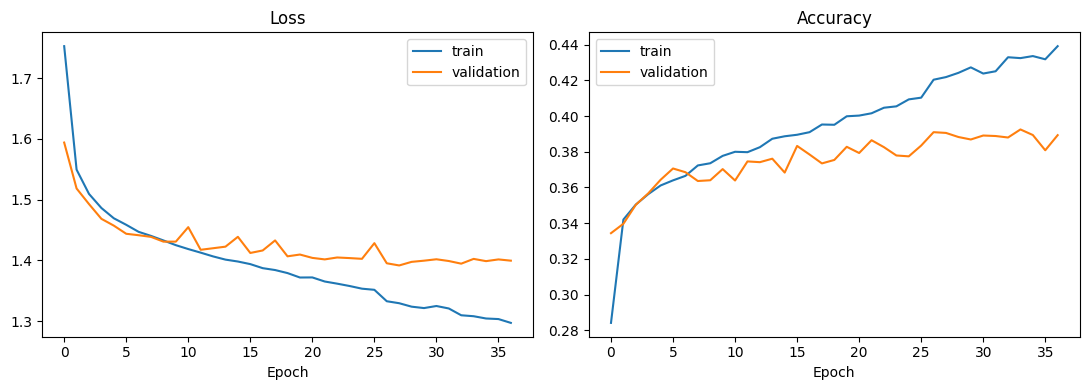

In [8]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(history['train_loss'],label='train');ax[0].plot(history['val_loss'],label='validation');ax[0].set_title('Loss');ax[0].set_xlabel('Epoch');ax[0].legend()
ax[1].plot(history['train_acc'],label='train');ax[1].plot(history['val_acc'],label='validation');ax[1].set_title('Accuracy');ax[1].set_xlabel('Epoch');ax[1].legend()
plt.tight_layout();plt.savefig('training_curves.png',dpi=160);plt.show()


## Test evaluation (run after hyperparameters have been selected using validation)


In [9]:
@torch.no_grad()
def predict(loader):
    model.eval(); all_probs=[]; all_y=[]
    for x,y in loader:
        prob=torch.softmax(model(x.to(device)),dim=1).cpu().numpy()
        all_probs.append(prob);all_y.append(y.numpy())
    return np.concatenate(all_y),np.concatenate(all_probs)
y_true,probs=predict(test_loader)
y_pred=probs.argmax(1)
print('Test Accuracy:',accuracy_score(y_true,y_pred))
print('Test Macro F1:',f1_score(y_true,y_pred,average='macro',zero_division=0))
print(classification_report(y_true,y_pred,target_names=classes,zero_division=0))


Test Accuracy: 0.3921527777777778
Test Macro F1: 0.35973332247003353
              precision    recall  f1-score   support

       16PSK       0.25      0.10      0.14      1800
       16QAM       0.28      0.45      0.35      1800
      256QAM       0.31      0.36      0.33      1800
       32PSK       0.29      0.33      0.31      1800
       64QAM       0.20      0.03      0.05      1800
        8PSK       0.34      0.36      0.35      1800
        BPSK       0.76      0.88      0.81      1800
        QPSK       0.46      0.64      0.53      1800

    accuracy                           0.39     14400
   macro avg       0.36      0.39      0.36     14400
weighted avg       0.36      0.39      0.36     14400



 snr_db  accuracy  macro_f1   n
    -10  0.140625  0.124435 960
     -8  0.177083  0.155081 960
     -6  0.214583  0.193970 960
     -4  0.239583  0.212726 960
     -2  0.294792  0.274568 960
      0  0.320833  0.294207 960
      2  0.391667  0.367233 960
      4  0.454167  0.425751 960
      6  0.479167  0.455913 960
      8  0.493750  0.463003 960
     10  0.529167  0.484998 960
     12  0.534375  0.491050 960
     14  0.531250  0.493197 960
     16  0.530208  0.491785 960
     18  0.551042  0.513525 960


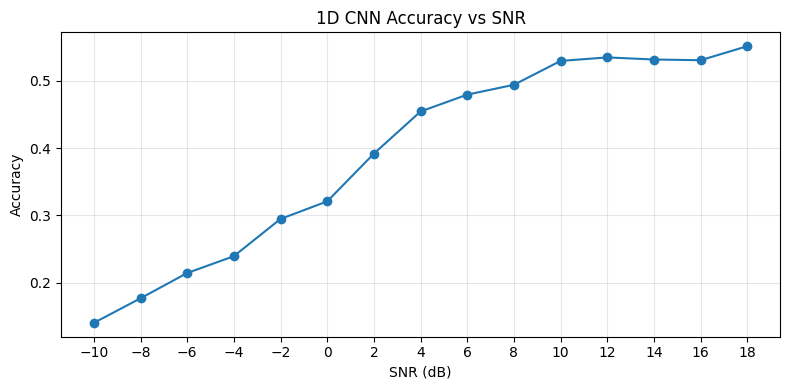

In [10]:
snr_test=test[2]
rows=[]
for s in sorted(np.unique(snr_test)):
    mask=snr_test==s
    rows.append({'snr_db':int(s),'accuracy':accuracy_score(y_true[mask],y_pred[mask]),'macro_f1':f1_score(y_true[mask],y_pred[mask],average='macro',zero_division=0),'n':int(mask.sum())})
snr_df=pd.DataFrame(rows)
snr_df.to_csv('cnn_accuracy_by_snr.csv',index=False)
print(snr_df.to_string(index=False))
plt.figure(figsize=(8,4));plt.plot(snr_df.snr_db,snr_df.accuracy,marker='o');plt.xticks(snr_df.snr_db);plt.xlabel('SNR (dB)');plt.ylabel('Accuracy');plt.title('1D CNN Accuracy vs SNR');plt.grid(alpha=.3);plt.tight_layout();plt.savefig('cnn_accuracy_vs_snr.png',dpi=160);plt.show()


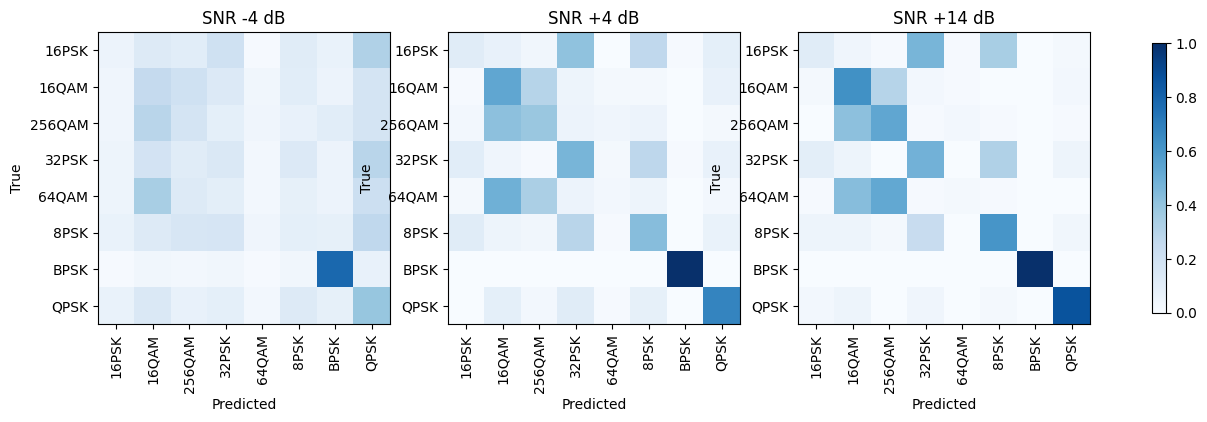

In [11]:
fig,axs=plt.subplots(1,3,figsize=(16,5))
for ax,s in zip(axs,[-4,4,14]):
    mask=snr_test==s
    cm=confusion_matrix(y_true[mask],y_pred[mask],labels=np.arange(len(classes)),normalize='true')
    im=ax.imshow(cm,vmin=0,vmax=1,cmap='Blues')
    ax.set_title(f'SNR {s:+d} dB');ax.set_xticks(range(len(classes)),classes,rotation=90);ax.set_yticks(range(len(classes)),classes)
    ax.set_xlabel('Predicted');ax.set_ylabel('True')
fig.colorbar(im,ax=axs.ravel().tolist(),shrink=0.7)
plt.savefig('cnn_confusion_matrices.png',dpi=160,bbox_inches='tight');plt.show()


In [12]:
# Inference latency: batch size 1, averaged over repeated passes, device-specific.
model.eval()
sample=torch.from_numpy(test[0][:1]).to(device)
with torch.no_grad():
    for _ in range(30): model(sample)
    if device.type=='cuda':torch.cuda.synchronize()
    t0=time.perf_counter()
    for _ in range(200): model(sample)
    if device.type=='cuda':torch.cuda.synchronize()
    latency_ms=(time.perf_counter()-t0)/200*1000

checkpoint={'model_state_dict':model.state_dict(),'classes':classes,'architecture':'CNN1D_three_blocks','input_shape':[2,128]}
torch.save(checkpoint,'cnn1d_best.pt')
model_mb=os.path.getsize('cnn1d_best.pt')/1024**2
summary={'accuracy':float(accuracy_score(y_true,y_pred)),'macro_f1':float(f1_score(y_true,y_pred,average='macro',zero_division=0)),'training_seconds':training_seconds,'parameters':sum(p.numel() for p in model.parameters()),'model_file_mb':model_mb,'single_sample_latency_ms':latency_ms,'device':str(device),'best_epoch':best_epoch,'classes':classes}
print(json.dumps(summary,indent=2))
with open('cnn_results.json','w') as f:json.dump(summary,f,indent=2)
# These row-level predictions can be joined by index with test manifests for dashboard use.
pd.DataFrame({'index':np.arange(len(y_true)),'true_label':[classes[i] for i in y_true],'predicted_label':[classes[i] for i in y_pred],'confidence':probs.max(axis=1),**{f'prob_{c}':probs[:,i] for i,c in enumerate(classes)}}).to_csv('cnn_test_predictions.csv',index=False)


{
  "accuracy": 0.3921527777777778,
  "macro_f1": 0.35973332247003353,
  "training_seconds": 604.3676773000007,
  "parameters": 53224,
  "model_file_mb": 0.21349048614501953,
  "single_sample_latency_ms": 0.4236670000000231,
  "device": "cpu",
  "best_epoch": 28,
  "classes": [
    "16PSK",
    "16QAM",
    "256QAM",
    "32PSK",
    "64QAM",
    "8PSK",
    "BPSK",
    "QPSK"
  ]
}


In [13]:
# Nén các kết quả để gửi cho các thành viên khác
files_to_export=['cnn1d_best.pt','cnn_results.json','cnn_accuracy_by_snr.csv','cnn_accuracy_vs_snr.png','cnn_confusion_matrices.png','training_curves.png','cnn_test_predictions.csv']
with zipfile.ZipFile('cnn1d_results.zip','w',zipfile.ZIP_DEFLATED) as out:
    for name in files_to_export:
        if os.path.exists(name): out.write(name)
print('Saved:', os.path.abspath('cnn1d_results.zip'))


Saved: d:\EE136_1D_CNN\cnn1d_results.zip


In [14]:
import zipfile

with zipfile.ZipFile("cnn1d_results.zip", "r") as z:
    print("Files in ZIP:")
    for name in z.namelist():
        print("-", name)

Files in ZIP:
- cnn1d_best.pt
- cnn_results.json
- cnn_accuracy_by_snr.csv
- cnn_accuracy_vs_snr.png
- cnn_confusion_matrices.png
- training_curves.png
- cnn_test_predictions.csv
